# 01 - Exploratory Data Analysis
IBM Telco Customer Churn. All logic lives in `src/`; this notebook calls it and explains the results. Charts are also saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import pandas as pd
from src.data_preprocessing import load_raw_data, clean_data, add_tenure_group
from src import eda
raw = load_raw_data()
clean = clean_data(raw)
df = add_tenure_group(clean)

## 1. Size, data types, missing values, duplicates

In [2]:
info = eda.dataset_overview(raw, clean)
print('Raw shape:', info['raw_shape'], '| Clean shape:', info['clean_shape'])
print('Blank/invalid TotalCharges:', info['blank_or_invalid_TotalCharges'])
print('Duplicate rows:', info['duplicate_rows_raw'], '| Duplicate customer IDs:', info['duplicate_ids_raw'])
raw.dtypes.to_frame('dtype')

Raw shape: (7043, 21) | Clean shape: (7043, 21)
Blank/invalid TotalCharges: 11
Duplicate rows: 0 | Duplicate customer IDs: 0


,dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


**What we see:** 7,043 customers and 21 columns. `TotalCharges` is read as text because 11 rows contain a blank space; they are converted to missing values (all have `tenure = 0`, i.e. brand-new customers) and filled later inside the model pipeline using training data only. No duplicate rows or IDs were found.

## 2. Churn vs non-churn

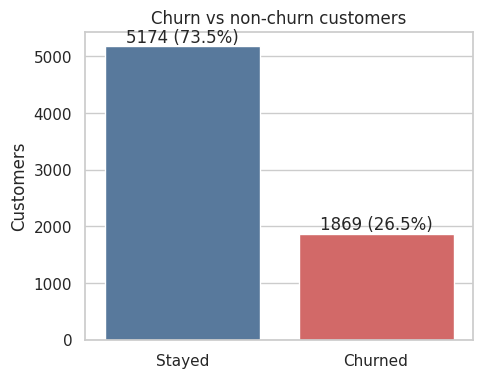

In [3]:
eda.plot_churn_distribution(df);

**What we see:** 1,869 of 7,043 customers (about 26.5%) churned. The classes are imbalanced, which is why accuracy alone is misleading (always guessing 'stay' would already be ~73% accurate).

## 3. Churn by contract type

,customers,churned,churn_rate
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


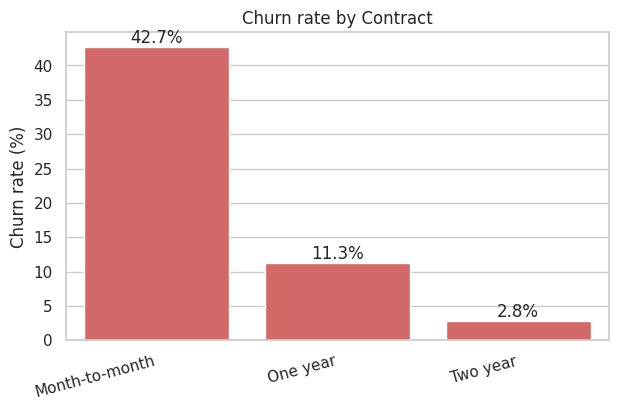

In [4]:
eda.plot_churn_rate_by(df, 'Contract', 'churn_by_contract.png');
eda.churn_rate_table(df, 'Contract')

**What we see:** month-to-month customers churn at 42.7%, one-year at 11.3% and two-year at 2.8%. Contract type is strongly *associated* with churn. It may reflect commitment, but this data cannot prove that switching contract would stop a customer leaving.

## 4. Churn by tenure and monthly charges

,tenure,MonthlyCharges
Churn,,
0,38.0,64.425
1,10.0,79.650


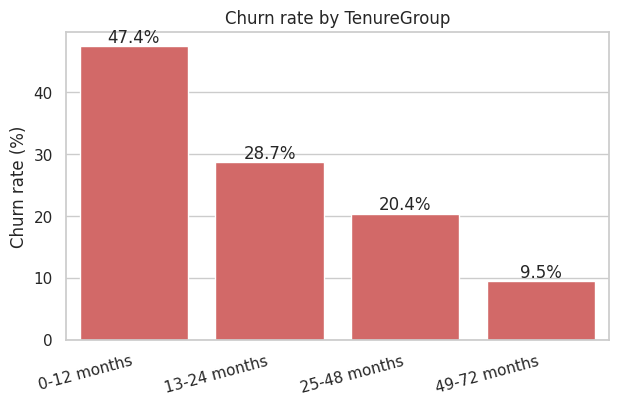

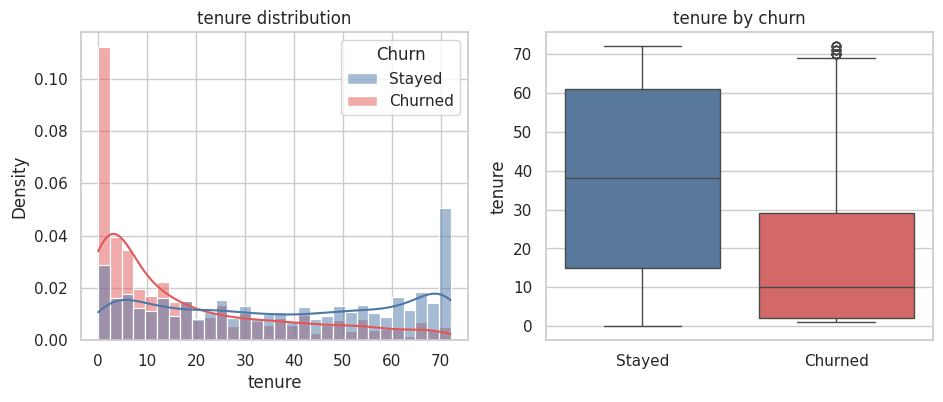

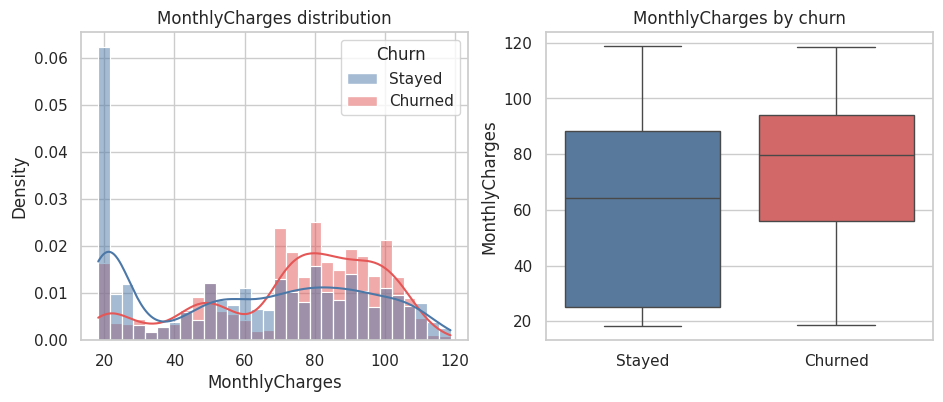

In [5]:
eda.plot_churn_rate_by(df, 'TenureGroup', 'churn_by_tenure_group.png', order=list(df['TenureGroup'].cat.categories));
eda.plot_numeric_by_churn(df, 'tenure', 'tenure_vs_churn.png');
eda.plot_numeric_by_churn(df, 'MonthlyCharges', 'monthly_charges_vs_churn.png');
df.groupby('Churn')[['tenure','MonthlyCharges']].median()

**What we see:** churn falls steadily with tenure (47.4% in the first year vs 9.5% after four years). The median churned customer had 10 months of tenure vs 38 for others, and paid a higher median monthly charge (about 79.65 vs 64.43). Newer, higher-paying customers are more likely to leave in this data; the reasons are not in the data.

## 5. Churn by payment method and internet service

,customers,churned,churn_rate
PaymentMethod,,,
Electronic check,2365,1071,45.3
Mailed check,1612,308,19.1
Bank transfer (automatic),1544,258,16.7
Credit card (automatic),1522,232,15.2


,customers,churned,churn_rate
InternetService,,,
Fiber optic,3096,1297,41.9
DSL,2421,459,19.0
No,1526,113,7.4


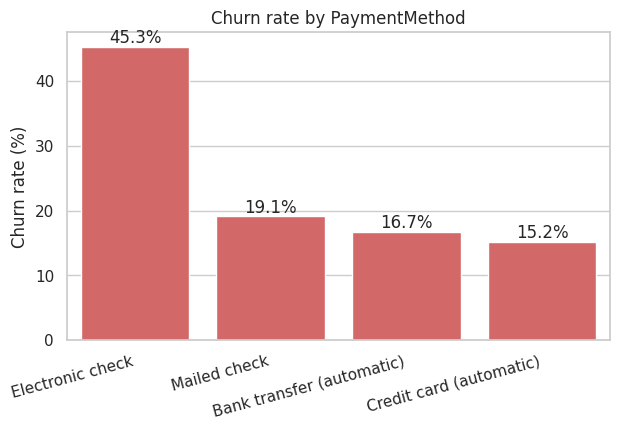

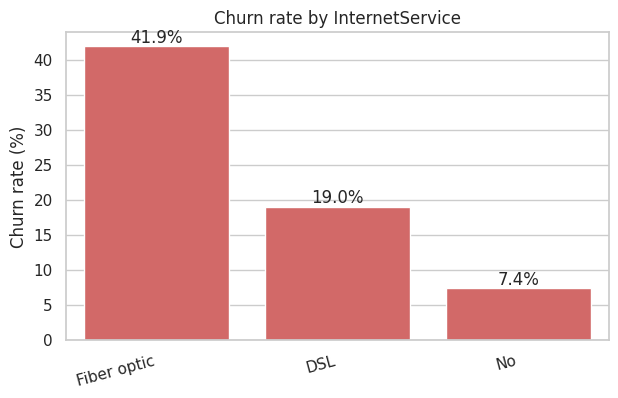

In [6]:
eda.plot_churn_rate_by(df, 'PaymentMethod', 'churn_by_payment_method.png');
eda.plot_churn_rate_by(df, 'InternetService', 'churn_by_internet_service.png');
display(eda.churn_rate_table(df, 'PaymentMethod'))
eda.churn_rate_table(df, 'InternetService')

**What we see:** electronic-check payers churn at 45.3%, versus 15-19% for the other three methods. Fiber-optic customers churn at 41.9%, DSL at 19.0%, and customers with no internet service at 7.4%. These groups also differ in contract type and price, so each pattern may partly reflect other factors (confounding).

## 6. Correlations of numeric features

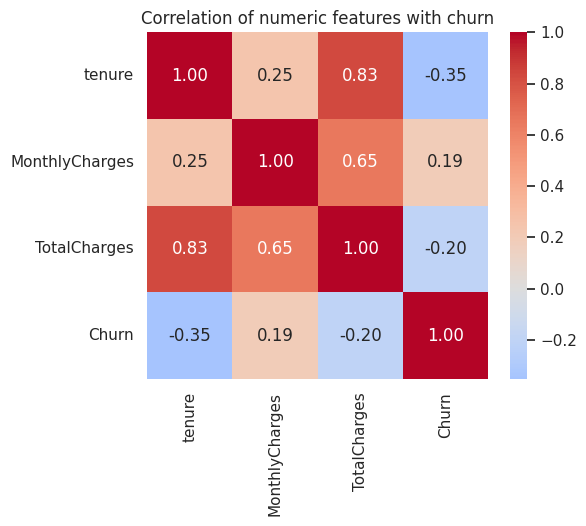

In [7]:
eda.plot_correlation(df);

**What we see:** churn is negatively correlated with `tenure` (-0.35), mildly positively with `MonthlyCharges` (+0.19) and mildly negatively with `TotalCharges` (-0.20). `TotalCharges` is largely tenure x monthly charge, so those features overlap. Correlation is not causation.